# Bài 6 — UCB1, cây giới hạn ở độ sâu 1

Thực hiện: Ly. Công cụ hỗ trợ: OpenAI Codex (code và kiểm thử). Người nộp cần tự đọc và xác nhận kết quả.

## Quy tắc và bộ trạng thái chung

Import API đóng băng từ `tictactoe.py`. T1–T4 trùng protocol nhóm; X là người được đánh giá trên bộ trạng thái. T3 được giữ nguyên từ đề dù số quân không mô tả lượt X trong một ván bắt đầu bằng X; đây là fixture search, không dùng để khởi đầu thi đấu.

In [1]:
from pathlib import Path
from time import perf_counter
from collections import Counter
from functools import lru_cache
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from tictactoe import empty_board, actions, result, utility, other
SEED = 42
REPEATS = 30
GAMES_PER_ROLE = 100
DEBUG = 0

# Cache only deterministic rules; every simulated trajectory is still random.
@lru_cache(None)
def cached_utility(state, player):
    return utility(list(state), player)

@lru_cache(None)
def legal_actions(state):
    return tuple(actions(list(state)))

def playout(board, action, player='x', rng=None):
    rng = np.random.default_rng() if rng is None else rng
    state = tuple(result(list(board), player, action))
    current = other(player)
    while True:
        value = cached_utility(state, player)
        if value is not None:
            return value
        move = int(rng.choice(legal_actions(state)))
        state = tuple(result(list(state), current, move))
        current = other(current)

@lru_cache(None)
def exact_value(state, player):
    value = cached_utility(state, player)
    if value is not None:
        return value
    return max(-exact_value(tuple(result(list(state), player, a)), other(player))
               for a in legal_actions(state))

def optimal_moves(board, player='x'):
    values = {a: -exact_value(tuple(result(list(board), player, a)), other(player))
              for a in legal_actions(tuple(board))}
    best = max(values.values())
    return best, {a for a, value in values.items() if value == best}

STATES = {
    'T1 X sap thang': ['x','o',' ','o','x',' ',' ',' ',' '],
    'T2 X can hoa': ['x','o','x',' ','o',' ',' ',' ',' '],
    'T3 bat loi': ['o',' ','x',' ',' ',' ',' ',' ','o'],
    'T4 ban rong': empty_board(),
}
display(pd.DataFrame([{'state': label, 'board': ''.join(c if c != ' ' else '.' for c in b),
                       'optimal_value': optimal_moves(b)[0],
                       'optimal_moves': sorted(optimal_moves(b)[1])}
                      for label, b in STATES.items()]))
print({'seed': SEED, 'repeats': REPEATS, 'games_per_role': GAMES_PER_ROLE,
       'Python': platform.python_version(), 'NumPy': np.__version__})

def markdown_table(frame):
    headers = [str(c) for c in frame.columns]
    rows = ['|' + '|'.join(headers) + '|', '|' + '|'.join(['---'] * len(headers)) + '|']
    for row in frame.itertuples(index=False, name=None):
        rows.append('|' + '|'.join(f'{v:.6f}' if isinstance(v, float) else str(v) for v in row) + '|')
    return '\n'.join(rows)

def record_section(key, text):
    path = Path('results/ly_results.md')
    path.parent.mkdir(exist_ok=True)
    old = path.read_text(encoding='utf-8') if path.exists() else '# Kết quả cá nhân — Ly\n\n'
    begin, end = f'<!-- BEGIN {key} -->', f'<!-- END {key} -->'
    block = begin + '\n' + text + '\n' + end
    if begin in old:
        start = old.index(begin)
        stop = old.index(end, start) + len(end)
        old = old[:start] + block + old[stop:]
    else:
        old += '\n' + block + '\n'
    path.write_text(old, encoding='utf-8')

,state,board,optimal_value,optimal_moves
0,T1 X sap thang,xo.ox....,1,"[2, 6, 8]"
1,T2 X can hoa,xox.o....,0,[7]
2,T3 bat loi,o.x.....o,-1,"[1, 3, 4, 5, 6, 7]"
3,T4 ban rong,.........,0,"[0, 1, 2, 3, 4, 5, 6, 7, 8]"


{'seed': 42, 'repeats': 30, 'games_per_role': 100, 'Python': '3.13.5', 'NumPy': '2.3.4'}


## Thuật toán

Đây là UCB1 tại gốc, **không phải MCTS đầy đủ**. Mỗi nước chưa thử được thăm trước. Sau đó chọn theo $Q_a + \sqrt{2\ln(t)/n_a}$: exploitation $Q_a=(\bar u_a+1)/2$ là reward trung bình chuẩn hóa về [0,1]; exploration tăng cho nước ít được thăm. Sau N mô phỏng, chọn nước đã thăm có utility trung bình lớn nhất; exploration chỉ dùng khi cấp ngân sách. N lớn cho phép ước lượng lại nhiều nước hơn, nhưng không bảo đảm độ ổn định tăng ở mọi trạng thái.

In [2]:
ALGORITHM = 'UCB1'
BUDGETS = [10, 100]

def monte_carlo_search(board, N=100, player='x', seed=42):
    if isinstance(N, bool) or not isinstance(N, (int, np.integer)) or N < 1:
        raise ValueError('N must be a positive integer')
    started = perf_counter()
    if utility(board, player) is not None:
        raise ValueError('Cannot search a terminal board')
    rng = np.random.default_rng(seed)
    order = [int(a) for a in rng.permutation(actions(board))]
    visits, totals = {a: 0 for a in order}, {a: 0.0 for a in order}
    for t in range(N):
        unvisited = [a for a in order if not visits[a]]
        if unvisited:
            action = unvisited[0]
        else:
            action = max(order, key=lambda a: (totals[a] / visits[a] + 1) / 2
                         + np.sqrt(2 * np.log(t) / visits[a]))
        totals[action] += playout(board, action, player, rng)
        visits[action] += 1
    means = {a: totals[a] / visits[a] if visits[a] else None for a in order}
    move = max((a for a in order if visits[a]), key=means.get)
    return {'move': move, 'value': means[move], 'visits': visits, 'action_values': means,
            'playouts': sum(visits.values()), 'elapsed_s': perf_counter() - started}

def UCT_depth1(board, N=100, player='x', seed=42):
    return monte_carlo_search(board, N, player, seed)['move']

In [3]:
# Meaningful invariants: exact budget, seeded results, legality, input preserved.
for board in STATES.values():
    before = board.copy()
    for budget in (1, 10, 100):
        a = monte_carlo_search(board, budget, seed=42)
        b = monte_carlo_search(board, budget, seed=42)
        assert a['move'] in actions(board)
        assert a['playouts'] == budget == sum(a['visits'].values())
        assert (a['move'], a['action_values'], a['visits']) == (b['move'], b['action_values'], b['visits'])
        assert -1 <= a['value'] <= 1
        assert board == before
print('Budget / seed / legality / no-mutation checks passed')

Budget / seed / legality / no-mutation checks passed


## Độ ổn định — 30 seed cho mỗi trạng thái và ngân sách

Báo tỷ lệ nước phổ biến nhất, toàn bộ tần suất và tỷ lệ chọn nước tối ưu. Cache utility chỉ lưu luật xác định, không lưu kết quả rollout. Thời gian sau warm-up không gồm hiển thị.

,state,N,modal_move,modal_rate,optimal_rate,mean_ms,move_counts
0,T1 X sap thang,10,6,0.333333,0.866667,1.015033,"{2: 7, 5: 2, 6: 10, 7: 2, 8: 9}"
1,T1 X sap thang,100,8,1.000000,1.000000,7.412710,{8: 30}
2,T2 X can hoa,10,7,0.433333,0.433333,0.958983,"{3: 6, 5: 4, 6: 6, 7: 13, 8: 1}"
3,T2 X can hoa,100,7,0.966667,0.966667,9.990457,"{3: 1, 7: 29}"
4,T3 bat loi,10,4,0.500000,1.000000,1.267973,"{1: 1, 3: 1, 4: 15, 5: 1, 6: 10, 7: 2}"
5,T3 bat loi,100,4,1.000000,1.000000,12.975183,{4: 30}
6,T4 ban rong,10,4,0.200000,1.000000,3.575757,"{0: 2, 1: 3, 2: 3, 3: 4, 4: 6, 5: 4, 6: 2, 7: ..."
7,T4 ban rong,100,4,0.433333,1.000000,24.456347,"{0: 3, 2: 3, 3: 1, 4: 13, 5: 1, 6: 5, 8: 4}"


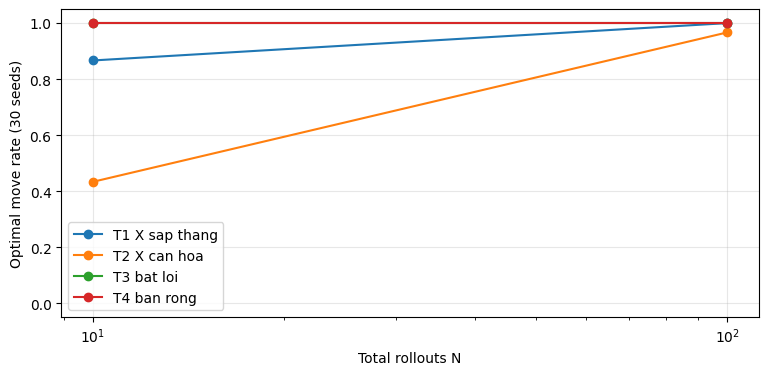

In [4]:
# One warm-up per state and budget, outside the timer.
rows = []
for state, board in STATES.items():
    optimal_value, optimal = optimal_moves(board)
    for budget in BUDGETS:
        monte_carlo_search(board, budget, seed=SEED)
        measurements = [monte_carlo_search(board, budget, seed=seed) for seed in range(REPEATS)]
        counts = Counter(item['move'] for item in measurements)
        mode, frequency = counts.most_common(1)[0]
        rows.append({'state': state, 'N': budget, 'modal_move': mode,
                     'modal_rate': frequency / REPEATS,
                     'optimal_rate': sum(item['move'] in optimal for item in measurements) / REPEATS,
                     'mean_ms': 1000 * np.mean([item['elapsed_s'] for item in measurements]),
                     'move_counts': str(dict(sorted(counts.items())))})
stability = pd.DataFrame(rows)
display(stability)
fig, ax = plt.subplots(figsize=(9, 4))
for label, group in stability.groupby('state', sort=False):
    ax.plot(group['N'], group['optimal_rate'], marker='o', label=label)
ax.set(xscale='log', ylim=(-0.05, 1.05), xlabel='Total rollouts N', ylabel='Optimal move rate (30 seeds)')
ax.legend(); ax.grid(alpha=.3); plt.show()

### Nhận xét

Đồ thị dùng tỷ lệ tối ưu để phân biệt chất lượng với sự tập trung vào một nước. Ở T1 có nhiều nước thắng tối ưu; modal rate thấp không tự động là kém. T3 thua khi đối thủ tối ưu ở mọi nước, nên optimal rate ở T3 không thể hiện sức phòng thủ. Ở T4 mọi nước mở đầu đều có giá trị hòa khi hai bên chơi tối ưu, nên optimal rate cũng không phân biệt ưu thế trước Random. Phần nhận xét số liệu phía dưới ghi kết quả thực tế.

## Thi đấu với Random

Mỗi cấu hình bắt buộc N=10,100 chạy 100 ván ở từng vai. Thắng/hòa/thua tính từ góc nhìn agent; seed riêng cho agent và đối thủ. PMCS-1000 chỉ đo bộ trạng thái, không mở rộng giải đấu tùy chọn.

In [5]:
def play_vs_random(budget, role, n_games=100, seed=42):
    # Opponent has a separate stream; both roles use the same protocol.
    agent_rng, random_rng = np.random.default_rng(seed), np.random.default_rng(seed + 10000)
    counts = {'wins': 0, 'draws': 0, 'losses': 0}
    moves, elapsed = 0, 0.0
    monte_carlo_search(empty_board(), budget, player=role, seed=seed)  # warm-up
    for _ in range(n_games):
        board, player = empty_board(), 'x'
        while utility(board, role) is None:
            if player == role:
                start = perf_counter()
                action = monte_carlo_search(board, budget, player, int(agent_rng.integers(2**63)))['move']
                elapsed += perf_counter() - start
                moves += 1
            else:
                action = int(random_rng.choice(actions(board)))
            board = result(board, player, action)
            player = other(player)
        score = utility(board, role)
        counts[{1:'wins', 0:'draws', -1:'losses'}[score]] += 1
    assert sum(counts.values()) == n_games
    return {'agent': f'{ALGORITHM}-{budget}', 'role': role, **counts,
            'agent_moves': moves, 'total_agent_s': elapsed, 'mean_move_ms': 1000 * elapsed / moves}

# Required budgets: 100 games as X and 100 as O per agent.
match_results = pd.DataFrame([play_vs_random(N, role, GAMES_PER_ROLE, SEED)
                              for N in (10, 100) for role in ('x', 'o')])
display(match_results)

,agent,role,wins,draws,losses,agent_moves,total_agent_s,mean_move_ms
0,UCB1-10,x,94,4,2,389,0.534157,1.373155
1,UCB1-10,o,70,12,18,329,0.531750,1.616262
2,UCB1-100,x,99,1,0,339,5.102527,15.051701
3,UCB1-100,o,87,6,7,320,3.988652,12.464538


### Nhận xét và kết quả bàn giao

Tăng ngân sách thường tăng thời gian; random rollout đánh giá đối thủ ngẫu nhiên nên không bảo đảm tránh bẫy của đối thủ tối ưu. So sánh hai vai riêng vì lợi thế đi trước. Không suy ra thuật toán mạnh nhất chỉ từ vài fixture hoặc các trận với Random.

In [6]:
lines = []
for state, group in stability.groupby('state', sort=False):
    low, high = group.iloc[0], group.iloc[-1]
    lines.append(f"- {state}: optimal rate {low.optimal_rate:.1%} -> {high.optimal_rate:.1%}; "
                 f"modal rate {low.modal_rate:.1%} -> {high.modal_rate:.1%}; "
                 f"mean time {low.mean_ms:.3f} -> {high.mean_ms:.3f} ms.")
for row in match_results.itertuples():
    lines.append(f'- {row.agent} ({row.role}): W/D/L={row.wins}/{row.draws}/{row.losses}, '
                 f'{row.mean_move_ms:.3f} ms per agent move.')
comment = '\n'.join(lines)
display(Markdown(comment))
record_section(ALGORITHM, f'## Tic-Tac-Toe — {ALGORITHM}\n\n'
    'Seed 42; stability seeds 0..29; 100 games per role; warm-up excluded. '
    'Time = sum of agent decision time / number of agent moves; rendering excluded. '
    'N is the TOTAL simulation budget, not N per action.\n\n'
    + markdown_table(stability) + '\n\n' + markdown_table(match_results) + '\n\n' + comment
    + '\n\nModal frequency is stability, not correctness. Multiple optimal moves can reduce modal frequency. '
    'Optimal rate is checked against exact minimax; expected utility against random play does not guarantee minimax play. '
    'T3 has minimax value -1 for all legal moves, so its optimal rate alone is uninformative. '
    'These finite trials do not establish monotonic improvement or universal superiority.\n')

- T1 X sap thang: optimal rate 86.7% -> 100.0%; modal rate 33.3% -> 100.0%; mean time 1.015 -> 7.413 ms.
- T2 X can hoa: optimal rate 43.3% -> 96.7%; modal rate 43.3% -> 96.7%; mean time 0.959 -> 9.990 ms.
- T3 bat loi: optimal rate 100.0% -> 100.0%; modal rate 50.0% -> 100.0%; mean time 1.268 -> 12.975 ms.
- T4 ban rong: optimal rate 100.0% -> 100.0%; modal rate 20.0% -> 43.3%; mean time 3.576 -> 24.456 ms.
- UCB1-10 (x): W/D/L=94/4/2, 1.373 ms per agent move.
- UCB1-10 (o): W/D/L=70/12/18, 1.616 ms per agent move.
- UCB1-100 (x): W/D/L=99/1/0, 15.052 ms per agent move.
- UCB1-100 (o): W/D/L=87/6/7, 12.465 ms per agent move.